In [18]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import datasets, layers, models

In [14]:
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [7]:
(X_train, y_train), (X_test, y_test) = datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [15]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (60000, 28, 28)
y_train: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)


In [16]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

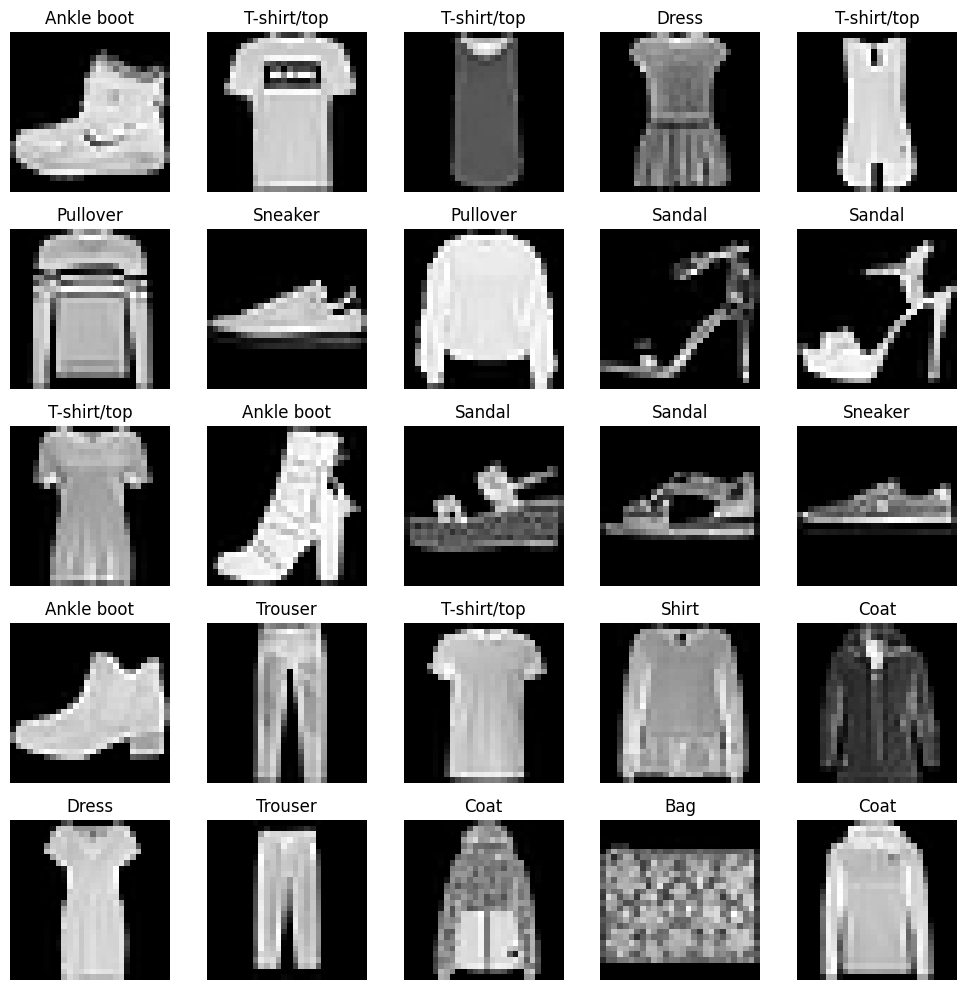

In [19]:
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [21]:
print(X_train.min())
print(X_train.max())

0.0
1.0


In [22]:
import pandas as pd

class_counts = pd.Series(y_train).value_counts().sort_index()

for i, count in enumerate(class_counts):
    print(f"{i} - {class_names[i]}: {count}")

0 - T-shirt/top: 6000
1 - Trouser: 6000
2 - Pullover: 6000
3 - Dress: 6000
4 - Coat: 6000
5 - Sandal: 6000
6 - Shirt: 6000
7 - Sneaker: 6000
8 - Bag: 6000
9 - Ankle boot: 6000


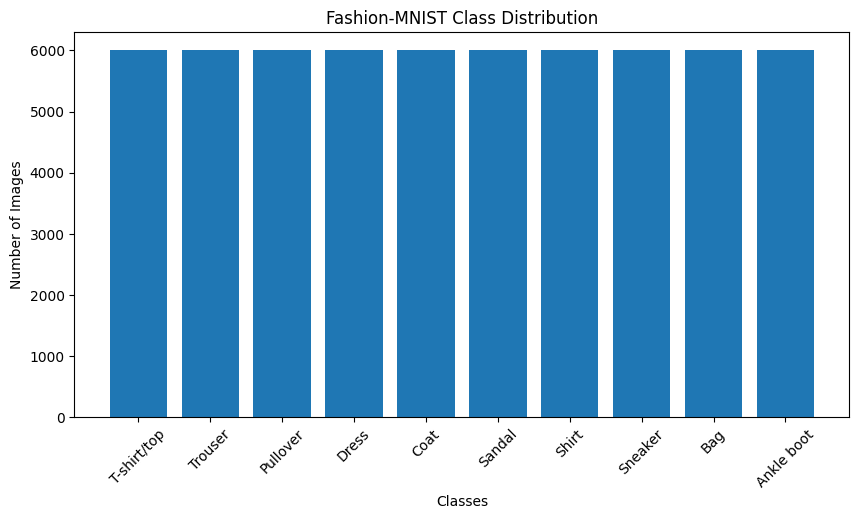

In [23]:
plt.figure(figsize=(10, 5))

plt.bar(class_names, class_counts)

plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.title("Fashion-MNIST Class Distribution")

plt.xticks(rotation=45)
plt.show()

In [24]:
print("Image shape:", X_train[0].shape)

Image shape: (28, 28)


In [26]:
model = models.Sequential([

    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation="softmax")
])

c:\Users\sambo\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
model.compile(
    optimizer='adam',
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [28]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - accuracy: 0.7808 - loss: 0.6111 - val_accuracy: 0.8422 - val_loss: 0.4365
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - accuracy: 0.8606 - loss: 0.3878 - val_accuracy: 0.8715 - val_loss: 0.3584
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - accuracy: 0.8775 - loss: 0.3371 - val_accuracy: 0.8788 - val_loss: 0.3368
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.8890 - loss: 0.3076 - val_accuracy: 0.8801 - val_loss: 0.3253
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.8969 - loss: 0.2841 - val_accuracy: 0.8923 - val_loss: 0.2976


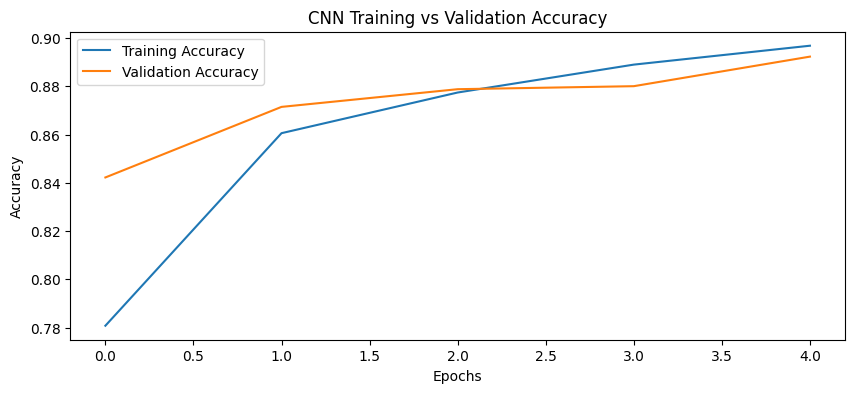

In [32]:
plt.figure(figsize=(10, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.show()

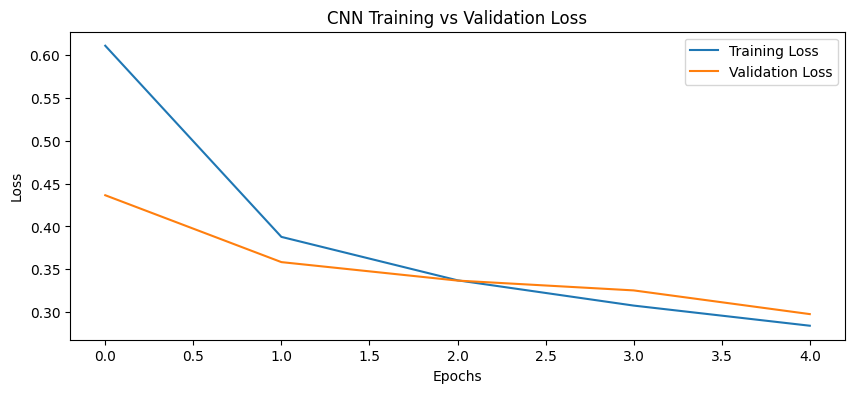

In [33]:
plt.figure(figsize=(10, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")
plt.legend()
plt.show()

In [34]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8873 - loss: 0.3134
Test Loss: 0.31336453557014465
Test Accuracy: 0.8873000144958496


In [35]:
y_pred_probs = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [36]:
print(y_pred_probs.shape)

(10000, 10)


In [37]:
y_pred = np.argmax(y_pred_probs, axis=1)

In [38]:
print(y_pred[:10])
print(y_test[:10])

[9 2 1 1 6 1 4 6 5 7]
[9 2 1 1 6 1 4 6 5 7]


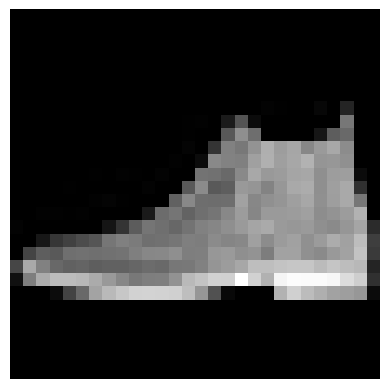

Actual: Ankle boot
Predicted: Ankle boot


In [39]:
index = 0

plt.imshow(X_test[index].squeeze(), cmap="gray")
plt.axis("off")
plt.show()

print("Actual:", class_names[y_test[index]])
print("Predicted:", class_names[y_pred[index]])

In [40]:
from sklearn.metrics import confusion_matrix, classification_report

In [41]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[908   1  26  11   6   1  41   0   6   0]
 [  4 973   1  15   3   1   1   0   2   0]
 [ 18   2 838   9  90   0  39   0   4   0]
 [ 35   6  14 884  32   0  23   0   6   0]
 [  1   1  47  31 882   0  37   0   1   0]
 [  0   0   0   2   0 967   0  19   0  12]
 [212   1  94  19 128   0 526   0  20   0]
 [  0   0   0   0   0  11   0 974   0  15]
 [  4   1   6   3   4   3   1   4 974   0]
 [  0   0   0   0   0   3   1  49   0 947]]


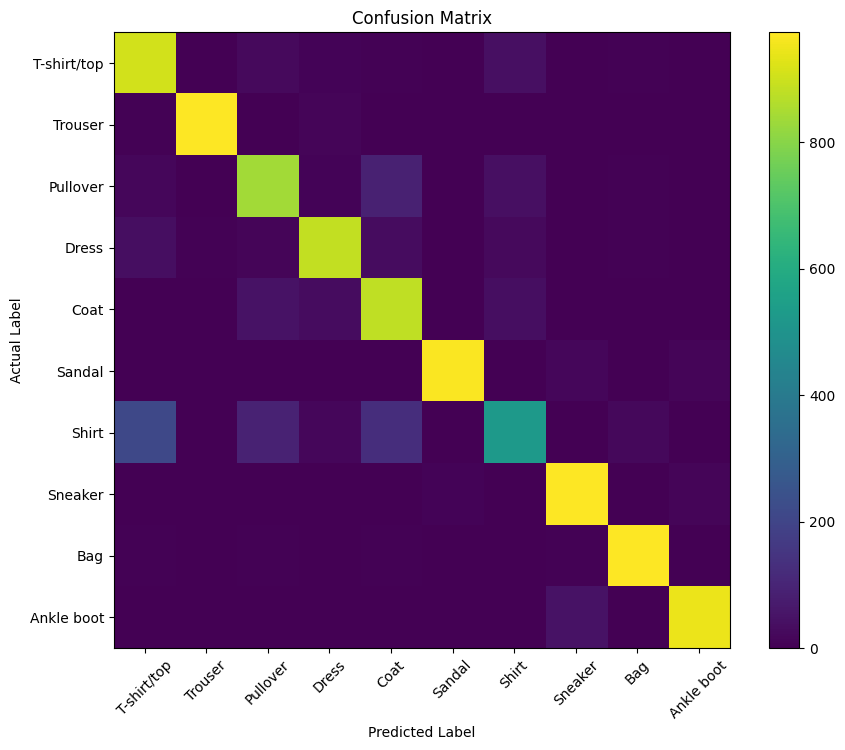

In [42]:
plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.colorbar()

plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)

plt.show()

In [43]:
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.77      0.91      0.83      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.82      0.84      0.83      1000
       Dress       0.91      0.88      0.90      1000
        Coat       0.77      0.88      0.82      1000
      Sandal       0.98      0.97      0.97      1000
       Shirt       0.79      0.53      0.63      1000
     Sneaker       0.93      0.97      0.95      1000
         Bag       0.96      0.97      0.97      1000
  Ankle boot       0.97      0.95      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.88     10000
weighted avg       0.89      0.89      0.88     10000



In [44]:
wrong_indices = np.where(y_pred != y_test)[0]

print("Total wrong predictions:", len(wrong_indices))

Total wrong predictions: 1127


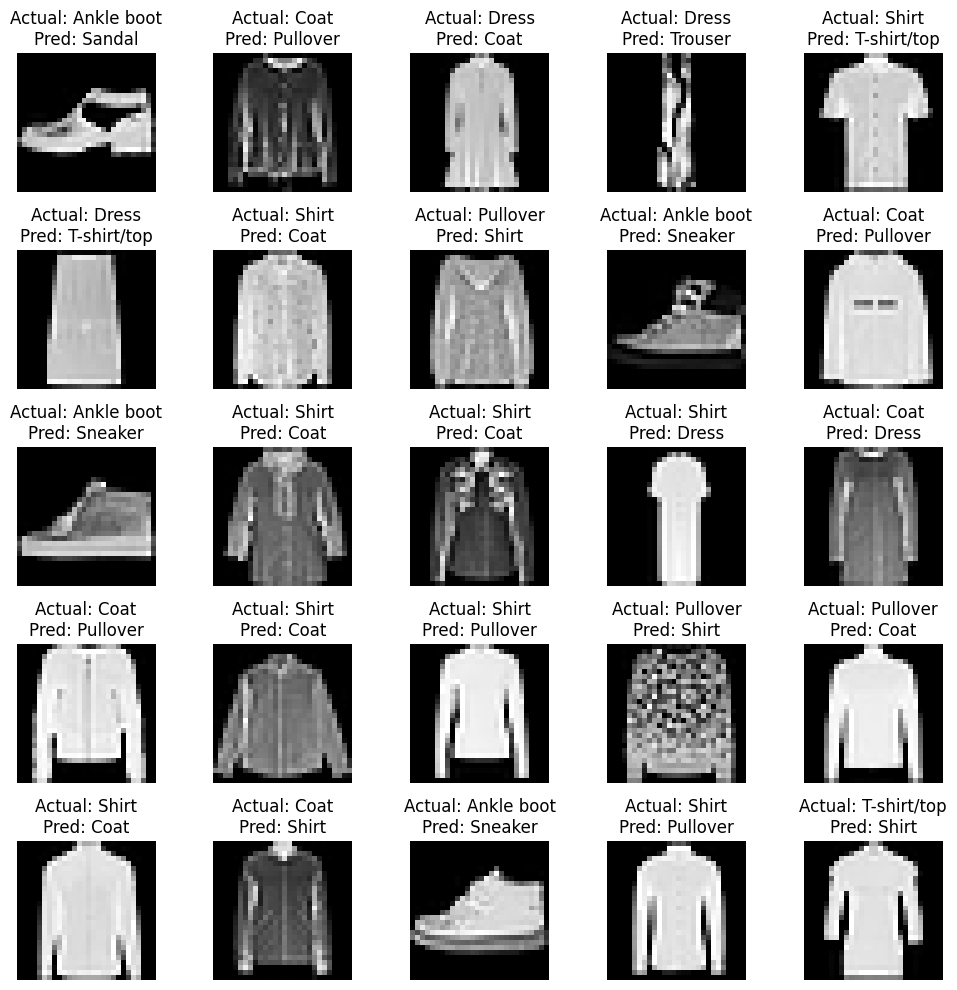

In [45]:
plt.figure(figsize=(10, 10))

for i, idx in enumerate(wrong_indices[:25]):
    plt.subplot(5, 5, i + 1)

    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [65]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
])

In [66]:
model2 = models.Sequential([
    
    layers.Input(shape=(28, 28, 1)),
    
    # Data augmentation
    data_augmentation,
    
    # CNN block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # CNN block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # CNN block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten
    layers.Flatten(),
    
    # Dense
    layers.Dense(128, activation="relu"),
    
    # Dropout
    layers.Dropout(0.5),
    
    # Output
    layers.Dense(10, activation="softmax")
])

In [67]:
model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [68]:
model2.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_5 (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,474 (431.54 KB)

 Trainable params: 110,474 (431.54 KB)

 Non-trainable params: 0 (0.00 B)

In [69]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (60000, 28, 28, 1)
X_test: (10000, 28, 28, 1)


In [52]:
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

In [59]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (60000, 28, 28, 1)
X_test: (10000, 28, 28, 1)


In [70]:
history2 = model2.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    verbose=1
)

Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 43ms/step - accuracy: 0.5980 - loss: 1.0825 - val_accuracy: 0.7452 - val_loss: 0.6670
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - accuracy: 0.7238 - loss: 0.7427 - val_accuracy: 0.7603 - val_loss: 0.6549
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 43ms/step - accuracy: 0.7506 - loss: 0.6759 - val_accuracy: 0.7868 - val_loss: 0.5781
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 18s 38ms/step - accuracy: 0.7711 - loss: 0.6227 - val_accuracy: 0.7910 - val_loss: 0.5755
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 36ms/step - accuracy: 0.7823 - loss: 0.5942 - val_accuracy: 0.7933 - val_loss: 0.5605


In [71]:
test_loss2, test_accuracy2 = model2.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Improved Test Loss:", test_loss2)
print("Improved Test Accuracy:", test_accuracy2)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7947 - loss: 0.5816
Improved Test Loss: 0.5815567374229431
Improved Test Accuracy: 0.794700026512146


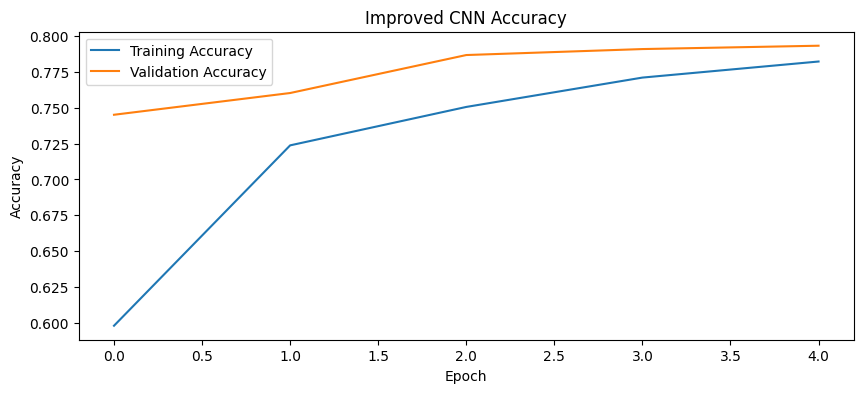

In [72]:
plt.figure(figsize=(10, 4))

plt.plot(history2.history["accuracy"], label="Training Accuracy")
plt.plot(history2.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Improved CNN Accuracy")
plt.legend()
plt.show()

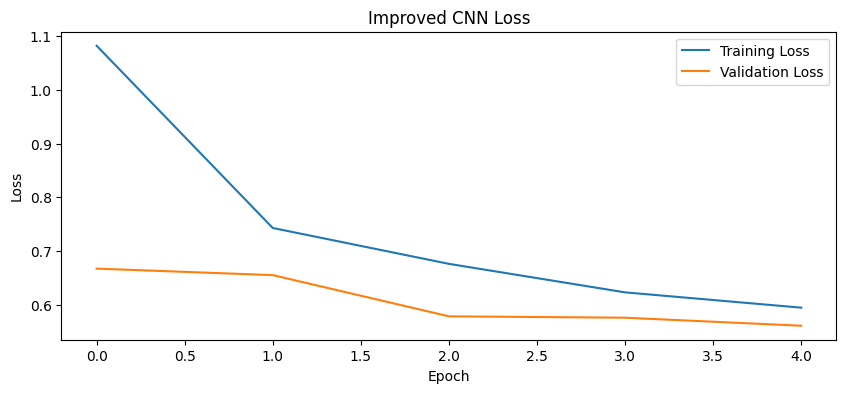

In [73]:
plt.figure(figsize=(10, 4))

plt.plot(history2.history["loss"], label="Training Loss")
plt.plot(history2.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved CNN Loss")
plt.legend()
plt.show()